In [1]:
pip install matplotlib


In [2]:
pip install scipy


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import scipy
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping


In [4]:
img_height, img_width = 224, 224
batch_size = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    'cosmetics_dataset',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    'cosmetics_dataset',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


Found 22 images belonging to 6 classes.
Found 3 images belonging to 6 classes.


In [5]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False  # on freeze la base

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

predictions = Dense(train_generator.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [6]:
early_stop = EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/10
2/2 [==============================] - 4s 2s/step - loss: 2.2590 - accuracy: 0.1364 - val_loss: 2.7694 - val_accuracy: 0.0000e+00
Epoch 2/10
2/2 [==============================] - 1s 667ms/step - loss: 2.0625 - accuracy: 0.3636 - val_loss: 2.7188 - val_accuracy: 0.0000e+00
Epoch 3/10
2/2 [==============================] - 1s 406ms/step - loss: 2.2513 - accuracy: 0.2727 - val_loss: 2.6721 - val_accuracy: 0.0000e+00
Epoch 4/10
2/2 [==============================] - 1s 389ms/step - loss: 2.3048 - accuracy: 0.1818 - val_loss: 2.6274 - val_accuracy: 0.0000e+00
Epoch 5/10
2/2 [==============================] - 1s 633ms/step - loss: 2.1774 - accuracy: 0.1364 - val_loss: 2.5878 - val_accuracy: 0.0000e+00
Epoch 6/10
2/2 [==============================] - 1s 363ms/step - loss: 2.0594 - accuracy: 0.2273 - val_loss: 2.5494 - val_accuracy: 0.0000e+00
Epoch 7/10
2/2 [==============================] - 1s 561ms/step - loss: 1.8944 - accuracy: 0.4545 - val_loss: 2.5121 - val_accuracy: 0.0000

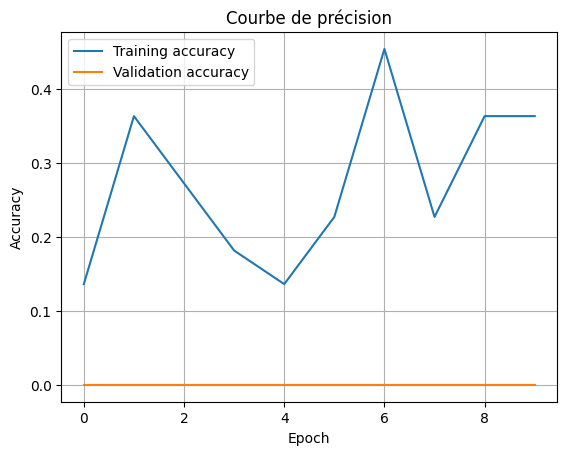

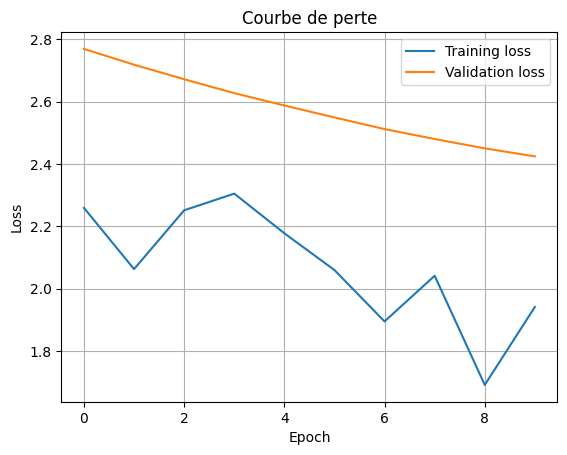

In [7]:
import matplotlib.pyplot as plt

# Courbe de la précision
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title("Courbe de précision")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Courbe de la perte
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Courbe de perte")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [8]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0

    preds = model.predict(img_array)
    class_index = np.argmax(preds)
    class_label = list(train_generator.class_indices.keys())[class_index]
    confidence = preds[0][class_index]
    
    print(f"✅ Prédiction : {class_label} ({confidence*100:.2f}%)")


In [9]:
predict_image(r"C:\Users\ayadi\Downloads\test deep.jpg")


1/1 [==============================] - 1s 758ms/step
✅ Prédiction : foundation (32.72%)


In [10]:
model.save("model_cosmetics.h5")
print("✅ Modèle sauvegardé avec succès.")


✅ Modèle sauvegardé avec succès.
